<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DEMO_WEEK_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1: Import Library dan Mount Google Drive

Mengimpor library dan memasang Google Drive hanya ketika berjalan di Google Colab.

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

try:
    from google.colab import drive
except ImportError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')

## Langkah 2: Load Dataset

Memuat gambar dan label dari folder training dan test.

In [ ]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "dataset/images/training/"
test_dir = "dataset/images/test"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


## Langkah 3: Preprocessing (Resize & Label Encoding)

Mengubah ukuran menjadi 256 ? 256 dan mengodekan day sebagai 1 serta night sebagai 0.

In [ ]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

## Langkah 4: Ekstraksi Fitur HOG (Histogram of Oriented Gradients)

Mengekstraksi fitur HOG dari gambar grayscale.

In [ ]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

## Langkah 5: Normalisasi Fitur

Menyesuaikan StandardScaler pada fitur training dan menerapkannya pada fitur test.

In [ ]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

## Langkah 6: Split Data Training & Validation

Membagi data training menjadi subset training dan validasi.

In [ ]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

## Langkah 7: Konversi Label ke Numpy Array

Mengonversi label menjadi array NumPy untuk Keras.

In [ ]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

## Langkah 8: Membangun Arsitektur Model Neural Network

Membangun dan mengompilasi neural network klasifikasi biner.

In [ ]:
# Build a simple feedforward neural network
# Define model architecture
# input_dim is the number of features in the dataset
# Hidden layer -> 128 neurons, ReLU activation
# Hidden layer -> 64 neurons, ReLU activation
# Output layer -> 1 neuron, Sigmoid activation (for binary classification)
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 9: Training Model

Melatih model selama 20 epoch dengan data validasi.

In [ ]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 17s 4s/step - accuracy: 0.3750 - loss: 1.0492

2/6 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6250 - loss: 0.9976

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.7292 - loss: 0.6963

4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7891 - loss: 0.5337

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8250 - loss: 0.4595

... (150 outputs left out)

4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 1.0000 - loss: 2.1162e-06

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 1.0000 - loss: 1.8283e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 1.0000 - loss: 1.5466e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 1.0000 - loss: 1.5466e-06 - val_accuracy: 0.9792 - val_loss: 0.1265


## Langkah 10: Evaluasi Model

Mengevaluasi loss dan akurasi pada data test.

In [ ]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.7500 - loss: 3.4677

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9312 - loss: 0.8620

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9312 - loss: 0.8620


Akurasi Test: 0.9312499761581421


## Langkah 11: Prediksi dan Laporan Klasifikasi serta Visualisasi

Membuat classification report, confusion matrix, dan grafik akurasi training serta validasi.

In [ ]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step 

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


              precision    recall  f1-score   support

           0       0.91      0.96      0.93        80
           1       0.96      0.90      0.93        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.93       160
weighted avg       0.93      0.93      0.93       160

[[77  3]
 [ 8 72]]


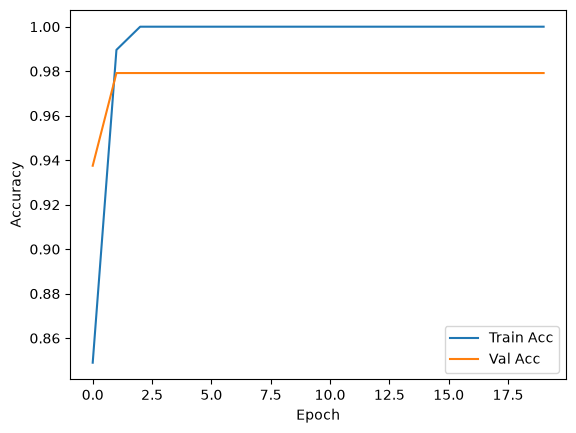

In [ ]:
# Visualize training history
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Langkah 12: Menyimpan Model dan Scaler

Menyimpan model dan scaler ke folder output.

In [ ]:
# Save the trained model
import pickle

Path('output').mkdir(exist_ok=True)

# 1. Simpan Model
# Menggunakan format .h5
model.save('output/day_night_model.h5')
print("Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open('output/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan sebagai: scaler.pkl")

Model berhasil disimpan sebagai: day_night_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
